In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data = {
    "x1": [0, 0, 1, 1],
    "x2": [0, 1, 0, 1],
    "label": [0, 1, 1, 1] 
}

df = pd.DataFrame(data)

df.head()

,x1,x2,label
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,1


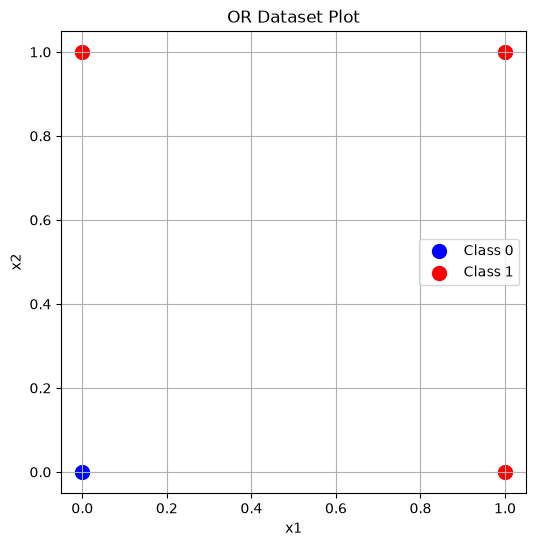

In [4]:
plt.figure(figsize=(6,6))

# Plot class 0
plt.scatter(df[df['label']==0]['x1'], 
            df[df['label']==0]['x2'], 
            c='blue', s=100, label='Class 0')

# Plot class 1
plt.scatter(df[df['label']==1]['x1'], 
            df[df['label']==1]['x2'], 
            c='red', s=100, label='Class 1')

plt.title("OR Dataset Plot")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)
plt.legend()
plt.show()

In [5]:
np.random.seed(42)
w1 = np.random.uniform(-1, 1)
w2 = np.random.uniform(-1, 1)
b  = np.random.uniform(-1, 1)

learning_rate = 0.1

w1 = -0.4
w2 = 0.2
b = -0.1

print("\nInitial Parameters:")
print(f"w1 = {w1:.3f}, w2 = {w2:.3f}, b = {b:.3f}")
print(f"Learning Rate = {learning_rate}")


Initial Parameters:
w1 = -0.400, w2 = 0.200, b = -0.100
Learning Rate = 0.1


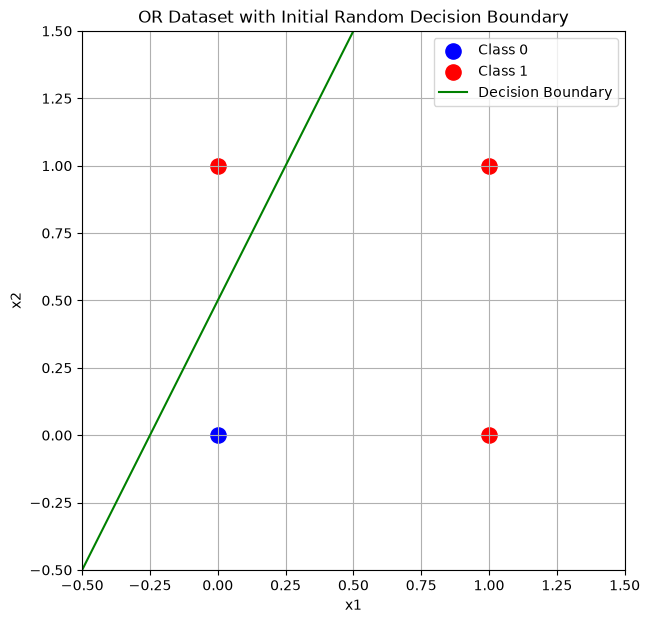

In [6]:
def plot_decision_boundary(w1, w2, b):
    x_vals = np.linspace(-0.5, 1.5, 100)
    
    if w2 != 0:
        y_vals = -(w1 * x_vals + b) / w2
    else:
        # vertical line if w2 = 0
        y_vals = np.zeros_like(x_vals)

    plt.plot(x_vals, y_vals, label="Decision Boundary", color="green")

plt.figure(figsize=(7,7))

# Plot class 0
plt.scatter(df[df['label']==0]['x1'],
            df[df['label']==0]['x2'],
            c='blue', s=120, label='Class 0')

# Plot class 1
plt.scatter(df[df['label']==1]['x1'],
            df[df['label']==1]['x2'],
            c='red', s=120, label='Class 1')

# Plot boundary
plot_decision_boundary(w1, w2, b)

plt.title("OR Dataset with Initial Random Decision Boundary")
plt.xlabel("x1")
plt.ylabel("x2")
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.grid(True)
plt.legend()
plt.show()

In [7]:
def plot_decision_boundary(df, w1, w2, b, epoch_num):
    plt.figure(figsize=(6,6))

    # Plot points
    plt.scatter(df[df['label']==0]['x1'], df[df['label']==0]['x2'],
                color='blue', s=120, label='Class 0')
    plt.scatter(df[df['label']==1]['x1'], df[df['label']==1]['x2'],
                color='red', s=120, label='Class 1')

    # Boundary
    x_vals = np.linspace(-0.5, 1.5, 100)

    if w2 != 0:
        y_vals = -(w1 * x_vals + b) / w2
        plt.plot(x_vals, y_vals, 'g', label="Decision Boundary")
    else:
        plt.axvline(-b/w1, color='green')

    plt.title(f"Decision Boundary After Epoch {epoch_num}")
    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.grid(True)
    plt.legend()
    plt.show()


# --------------------------
# Perceptron Training (Multiple Epochs)
# --------------------------
def perceptron_train(df, w1, w2, b, lr, epochs):

    for epoch in range(1, epochs+1):
        print(f"----EPOCH {epoch}----")

        correct = 0

        for i, row in df.iterrows():
            x1, x2, y = row["x1"], row["x2"], row["label"]

            # Prediction
            linear_output = w1*x1 + w2*x2 + b
            y_pred = 1 if linear_output >= 0 else 0

            # Count accuracy
            if y == y_pred:
                correct += 1

            # Error
            error = y - y_pred

            # Update
            w1 = w1 + lr * error * x1
            w2 = w2 + lr * error * x2
            b  = b  + lr * error

        # Accuracy for this epoch
        accuracy = correct / len(df)
        print(f"Accuracy after Epoch {epoch}: {accuracy*100:.2f}%")
        print(f"Updated Weights -> w1={w1:.3f}, w2={w2:.3f}, b={b:.3f}")

        # Visualize at end of epoch
        plot_decision_boundary(df, w1, w2, b, epoch)

    return w1, w2, b

----EPOCH 1----
Accuracy after Epoch 1: 50.00%
Updated Weights -> w1=-0.200, w2=0.300, b=0.100


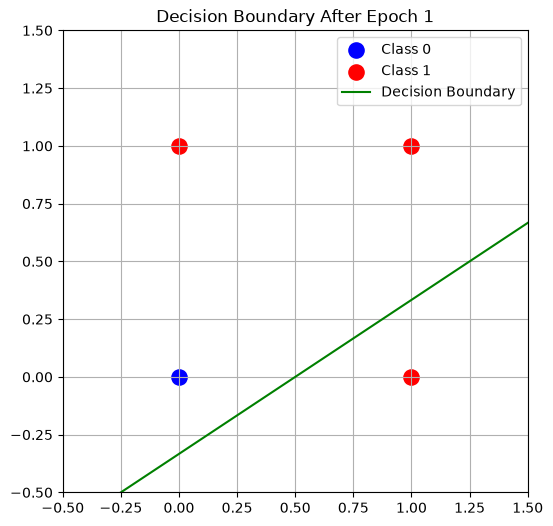

----EPOCH 2----
Accuracy after Epoch 2: 50.00%
Updated Weights -> w1=-0.100, w2=0.300, b=0.100


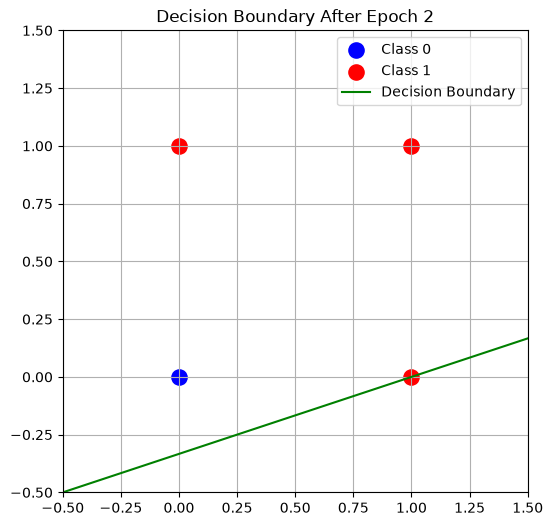

----EPOCH 3----
Accuracy after Epoch 3: 50.00%
Updated Weights -> w1=-0.000, w2=0.300, b=0.100


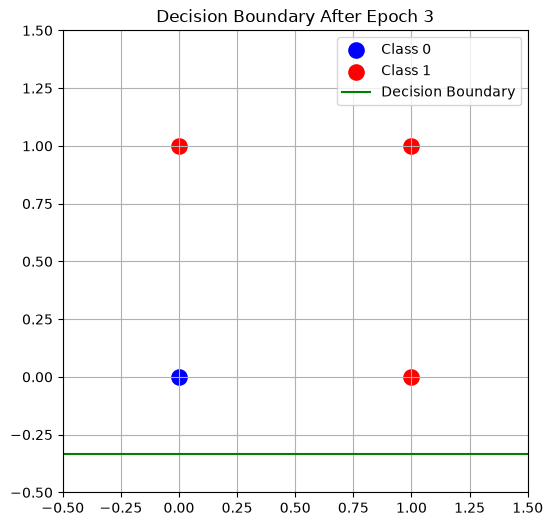

----EPOCH 4----
Accuracy after Epoch 4: 50.00%
Updated Weights -> w1=0.100, w2=0.300, b=0.100


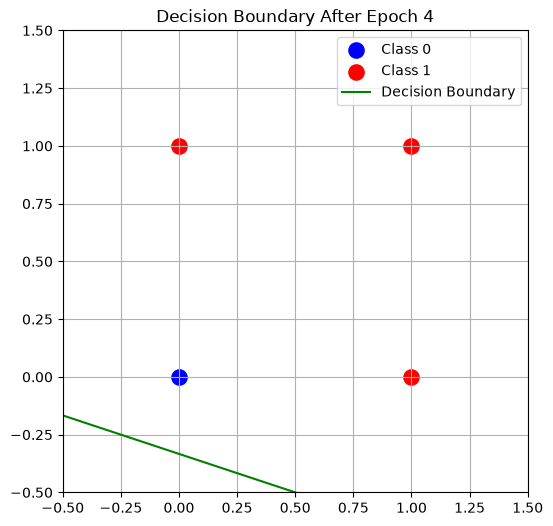

----EPOCH 5----
Accuracy after Epoch 5: 75.00%
Updated Weights -> w1=0.100, w2=0.300, b=0.000


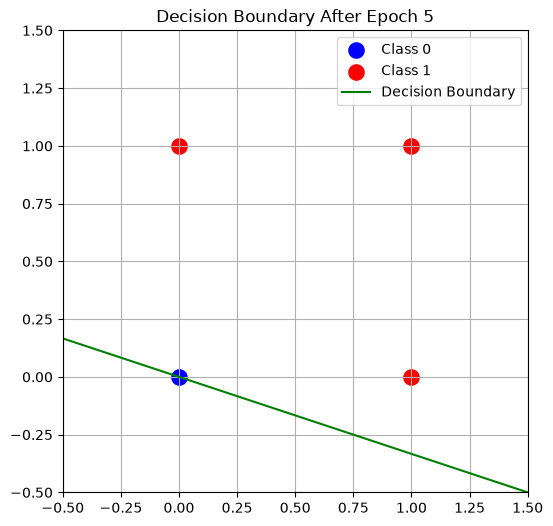

----EPOCH 6----
Accuracy after Epoch 6: 50.00%
Updated Weights -> w1=0.200, w2=0.300, b=0.000


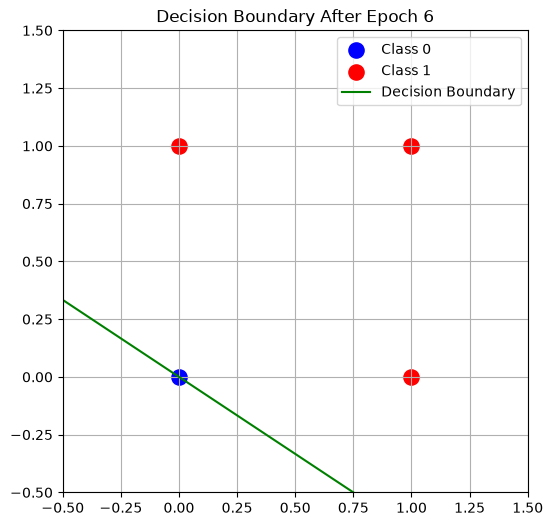

----EPOCH 7----
Accuracy after Epoch 7: 75.00%
Updated Weights -> w1=0.200, w2=0.300, b=-0.100


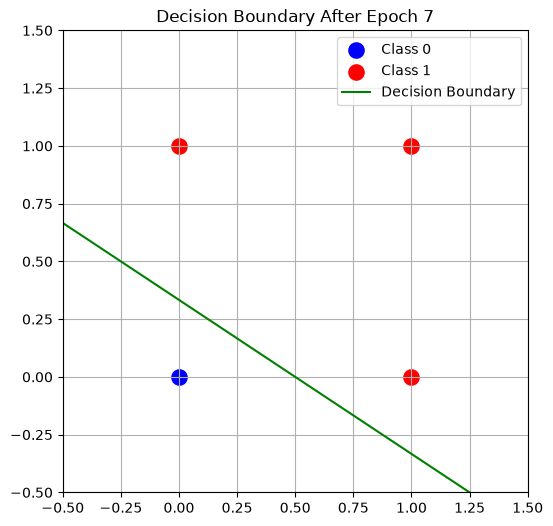

----EPOCH 8----
Accuracy after Epoch 8: 100.00%
Updated Weights -> w1=0.200, w2=0.300, b=-0.100


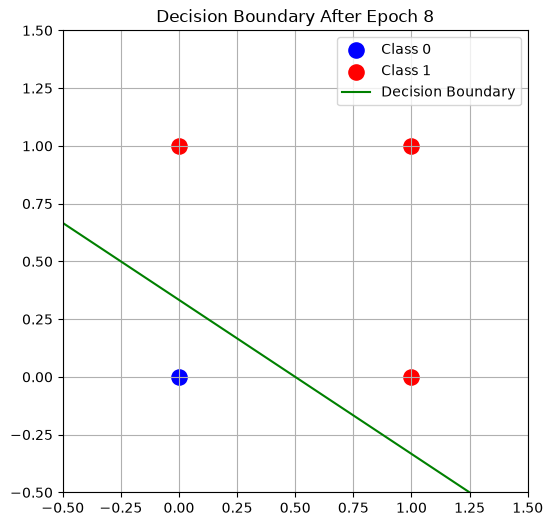

----EPOCH 9----
Accuracy after Epoch 9: 100.00%
Updated Weights -> w1=0.200, w2=0.300, b=-0.100


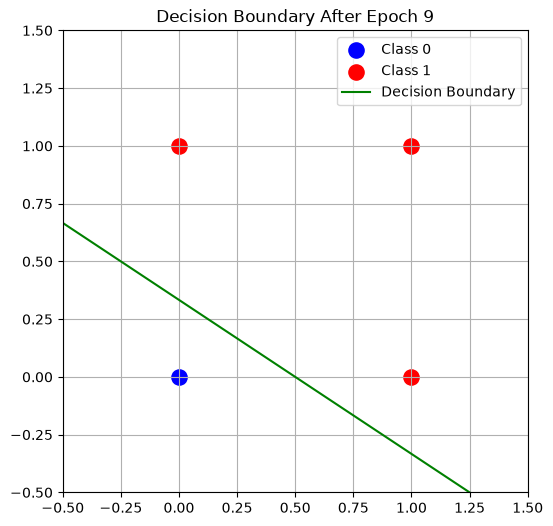

----EPOCH 10----
Accuracy after Epoch 10: 100.00%
Updated Weights -> w1=0.200, w2=0.300, b=-0.100


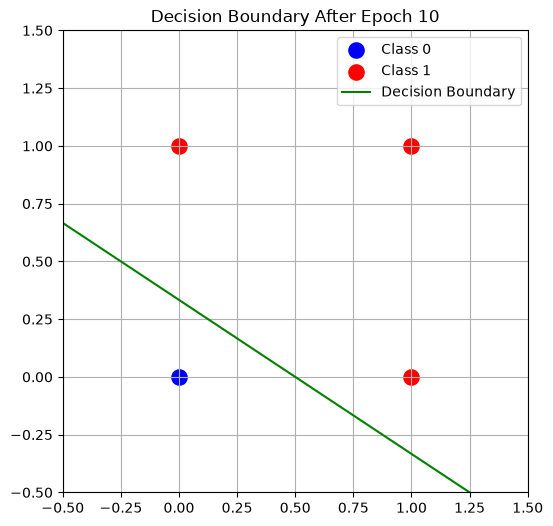


Final Predictions After Training:
Input=(0, 0) → Predicted=0, Actual=0
Input=(0, 1) → Predicted=1, Actual=1
Input=(1, 0) → Predicted=1, Actual=1
Input=(1, 1) → Predicted=1, Actual=1

Final Accuracy on Training Data = 100.00%


In [8]:
final_w1, final_w2, final_b = perceptron_train(df, w1, w2, b, learning_rate, epochs=10)

# ---- FINAL EVALUATION AFTER TRAINING ----
def predict(x1, x2, w1, w2, b):
    linear_output = w1*x1 + w2*x2 + b
    return 1 if linear_output >= 0 else 0

correct = 0
total = len(df)

print("\nFinal Predictions After Training:")
for i, row in df.iterrows():
    x1, x2, y = row["x1"], row["x2"], row["label"]
    y_pred = predict(x1, x2, final_w1, final_w2, final_b)
    print(f"Input=({x1}, {x2}) → Predicted={y_pred}, Actual={y}")
    if y_pred == y:
        correct += 1

accuracy = correct / total * 100
print(f"\nFinal Accuracy on Training Data = {accuracy:.2f}%")